# Cuaderno 3 — Explicación **paso a paso**: ¿por qué mi predicción con SVM es buena?

**Michael Lata · Técnicas de ML Supervisado**

Este cuaderno **no entrena nada nuevo**. Reutiliza el modelo y los datos que ya
prepararon los cuadernos anteriores (`01_Modelado` y `02_XAI`) y los explica **en
orden, con palabras sencillas** — como si se lo contáramos a alguien que nunca ha
visto un computador.

> **La idea en una frase:** queremos adivinar *cuántas unidades de un producto se
> venderán mañana*. Para eso miramos lo que pasó antes, lo ordenamos, lo pasamos por
> un "filtro" que pone todo en la misma escala, y una máquina (la SVM) traza la mejor
> línea posible para acertar. Al final comprobamos que **acierta más que el método
> usado en la Práctica 2**.

**Mapa de los pasos:**

| Paso | Qué explica |
|---|---|
| 1 | Qué queremos predecir |
| 2 | Cómo **entran** los datos (crudos) |
| 3 | Ordenar y resumir los datos |
| 4 | Crear "pistas" (las *features*) |
| 5 | El **filtro** (poner todo en la misma escala) |
| 6 | Cómo **decide** la SVM (margen y vectores de soporte) |
| 7 | La predicción en acción (un ejemplo real) |
| 8 | **Por qué es buena** (comparación con la Práctica 2) |
| 9 | En qué se fija el modelo |
| 10 | Resumen listo para las diapositivas |

## Preparación (cargar lo ya hecho)

Cargamos las herramientas, los **datos crudos** y el **modelo ya entrenado**.

In [1]:
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['figure.figsize'] = (9, 4); plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.alpha'] = 0.3

ART = Path('artefactos')
P2  = Path('/home/ing_michi/Documents/Aprendizaje Automatico/Practica_2')

# 1) datos crudos (tal cual salen del negocio)
sales = pd.read_csv(P2/'data'/'sales_history.csv', parse_dates=['fecha_venta'])

# 2) modelo ya entrenado + datos ya preparados + ficha de resultados
svr   = joblib.load(ART/'svr_demanda.joblib')      # la SVM de regresion
datos = np.load(ART/'datos_demanda.npz')
meta  = joblib.load(ART/'meta_demanda.joblib')
X_train, X_test = datos['X_train'], datos['X_test']
y_train, y_test = datos['y_train'], datos['y_test']
FEATURES = meta['features']
print('Todo cargado. Ventas crudas:', sales.shape, '| Modelo:', svr.named_steps['svr'])

Todo cargado. Ventas crudas: (1800, 5) | Modelo: SVR(C=10, epsilon=1.0, gamma=0.05)


## Paso 1 · ¿Qué queremos predecir?

**En simple:** una tienda quiere saber *cuántas unidades de cada producto venderá
**mañana***. Si lo sabe, compra ni de más (se le daña/ocupa bodega) ni de menos (se
queda sin vender).

**El símil:** es como el panadero que cada noche decide *cuánto pan amasar para
mañana*. No lo adivina al azar: mira cómo le fue los días pasados, si mañana es fin
de semana, si hay feriado... Eso mismo va a hacer nuestro modelo, pero con números.

## Paso 2 · ¿Cómo **entran** los datos?

**En simple:** los datos llegan *crudos*, como un cuaderno de ventas: cada renglón
es **una venta** (qué día, qué producto, cuántas unidades, cuánto stock había).
Así, sueltos, no sirven todavía — primero hay que ordenarlos.

In [2]:
print('Cada fila = una venta registrada. Primeras 5:')
sales[['fecha_venta','product_id','nombre','cantidad_vendida','stock_en_momento']].head()

Cada fila = una venta registrada. Primeras 5:


,fecha_venta,product_id,nombre,cantidad_vendida,stock_en_momento
0,2026-04-05,1,Laptop Gamer,2,316
1,2026-04-05,2,Monitor 4K,3,299
2,2026-04-05,3,Teclado Mecanico,5,303
3,2026-04-05,4,Raton Inal.,6,351
4,2026-04-05,5,Cable USB-C,7,330


## Paso 3 · Ordenar y resumir

**En simple:** juntamos todas las ventas del **mismo día y mismo producto** en una
sola línea (sumamos las unidades). Pasamos de *muchas ventas sueltas* a una tabla
limpia: **un día, un producto, cuánto se vendió**. Es como pasar las boletas del día
a un solo resumen por producto.

In [3]:
# resumimos por (fecha, producto) — igual que en la Practica 2
agg = (sales.groupby(['fecha_venta','product_id','nombre'])
            .agg(cantidad_vendida=('cantidad_vendida','sum'),
                 stock_promedio=('stock_en_momento','mean'))
            .reset_index()
            .sort_values(['product_id','fecha_venta']))
print('De', len(sales), 'ventas sueltas  ->', len(agg), 'filas resumidas (dia x producto)')
agg.head()

De 1800 ventas sueltas  -> 1800 filas resumidas (dia x producto)


,fecha_venta,product_id,nombre,cantidad_vendida,stock_promedio
0,2026-04-05,1,Laptop Gamer,2,316.0
10,2026-04-06,1,Laptop Gamer,6,314.0
20,2026-04-07,1,Laptop Gamer,7,308.0
30,2026-04-08,1,Laptop Gamer,10,301.0
40,2026-04-09,1,Laptop Gamer,5,291.0


## Paso 4 · Crear "pistas" (las *features*)

**En simple:** el modelo no entiende fechas ni nombres; entiende **números-pista**.
Para cada día le damos 12 pistas, agrupadas en 3 ideas fáciles:

| Tipo de pista | Qué le dice al modelo | Ejemplos |
|---|---|---|
| **Calendario** | en qué momento estamos | día de la semana, mes, ¿fin de semana?, ¿feriado? |
| **El pasado reciente** | cómo venía la venta | lo de ayer (`lag_1`), lo de hace 7 días (`lag_7`), el promedio (`rolling_mean_7`) |
| **El contexto** | situación del producto | stock disponible, categoría, cuánto se vendió hoy |

**El símil:** son las mismas pistas que usa el panadero — *"ayer vendí mucho",
*"mañana es domingo"*, *"queda poca harina"* — pero escritas como números.

> Detalle importante: las pistas del pasado se calculan **solo con días anteriores**
> (nunca con el futuro), para no hacer trampa.

In [4]:
# las 12 pistas que recibe el modelo
for i, f in enumerate(FEATURES, 1):
    print(f'{i:2d}. {f}')
print()
# asi se ve UNA fila ya convertida en pistas (la primera del conjunto de prueba):
ejemplo = pd.Series(X_test[0], index=FEATURES)
print('Ejemplo de un dia traducido a 12 numeros-pista:')
ejemplo

 1. cantidad_vendida
 2. dia_semana
 3. mes
 4. es_weekend
 5. es_feriado
 6. dias_desde_inicio
 7. proporcion_stock
 8. categoria_encoded
 9. lag_1
10. lag_7
11. rolling_mean_7
12. rolling_std_7

Ejemplo de un dia traducido a 12 numeros-pista:


cantidad_vendida      17.000000
dia_semana             4.000000
mes                    8.000000
es_weekend             0.000000
es_feriado             0.000000
dias_desde_inicio    145.000000
proporcion_stock       0.569832
categoria_encoded      0.000000
lag_1                  7.000000
lag_7                 11.000000
rolling_mean_7         8.857143
rolling_std_7          3.078342
dtype: float64

## Paso 5 · El **filtro**: poner todo en la misma escala

**En simple:** las pistas vienen en escalas muy distintas. "Día de la semana" va de
0 a 6, pero "unidades vendidas" puede ser 50. Si no las emparejamos, el modelo le
haría más caso a la pista de números grandes solo por ser grande, no por ser
importante. El **filtro** (`StandardScaler`) reescala **cada pista** para que todas
queden centradas en 0 y con tamaño parecido. **Misma regla, mismo peso para todas.**

**El símil:** es como traducir pesos, dólares y euros a una **moneda común** antes
de compararlos. Sin eso, comparar sería injusto.

Abajo se ve una pista **antes** (números dispares) y **después** del filtro (todas
alrededor de 0).

In [5]:
scaler = svr.named_steps['sc']          # el filtro que aprendio del entrenamiento
X_test_filtrado = scaler.transform(X_test)

comp = pd.DataFrame({
    'pista': FEATURES,
    'ANTES (rango real)':   [f'{X_test[:,i].min():.1f}  a  {X_test[:,i].max():.1f}' for i in range(len(FEATURES))],
    'DESPUES (filtrado)':   [f'{X_test_filtrado[:,i].min():.1f}  a  {X_test_filtrado[:,i].max():.1f}' for i in range(len(FEATURES))],
})
print(comp.to_string(index=False))

            pista ANTES (rango real) DESPUES (filtrado)
 cantidad_vendida       0.0  a  41.0       -2.0  a  3.3
       dia_semana        0.0  a  6.0       -1.5  a  1.5
              mes        8.0  a  9.0        1.4  a  2.2
       es_weekend        0.0  a  1.0       -0.6  a  1.6
       es_feriado        0.0  a  0.0      -0.1  a  -0.1
dias_desde_inicio    145.0  a  178.0        1.7  a  2.6
 proporcion_stock        0.0  a  0.6       -1.8  a  1.7
categoria_encoded        0.0  a  3.0       -1.5  a  1.5
            lag_1       0.0  a  41.0       -2.0  a  3.3
            lag_7       0.0  a  43.0       -2.0  a  3.6
   rolling_mean_7       8.0  a  26.9       -1.4  a  2.1
    rolling_std_7       1.4  a  14.0       -1.2  a  2.9


/tmp/claude-1000/ipykernel_12460/1737487420.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot(X_test, vert=False, labels=FEATURES)
/tmp/claude-1000/ipykernel_12460/1737487420.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot(X_test_filtrado, vert=False, labels=FEATURES)


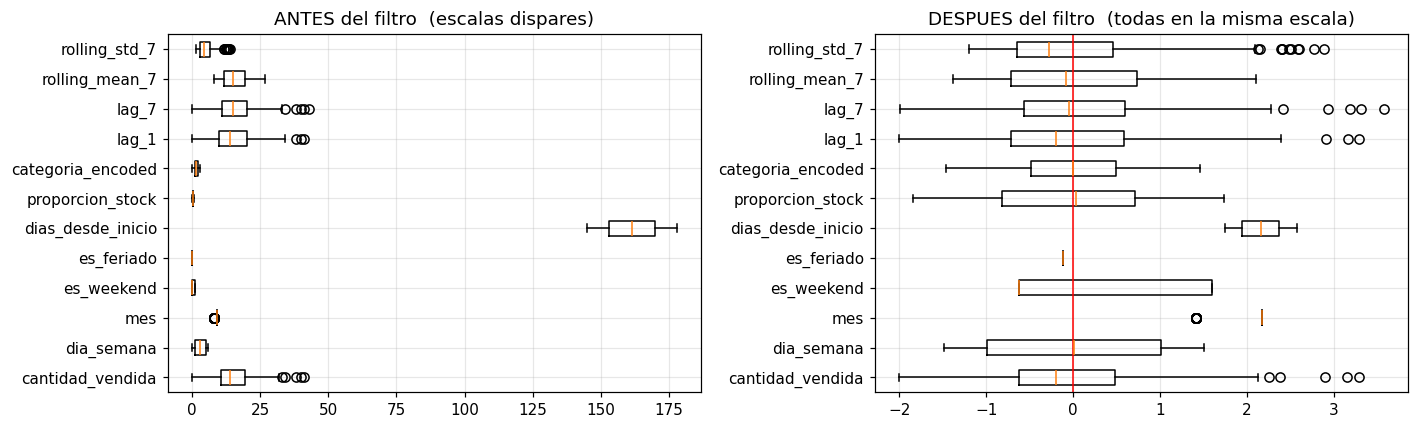

In [6]:
# lo mismo, en grafico: antes el rango es disparejo; despues, parejo
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].boxplot(X_test, vert=False, labels=FEATURES)
ax[0].set_title('ANTES del filtro  (escalas dispares)')
ax[1].boxplot(X_test_filtrado, vert=False, labels=FEATURES)
ax[1].set_title('DESPUES del filtro  (todas en la misma escala)')
ax[1].axvline(0, color='red', lw=1)
plt.tight_layout(); plt.show()

## Paso 6 · ¿Cómo **decide** la SVM?

**En simple:** una vez que todas las pistas están parejas, la SVM busca **la mejor
regla para acertar**. No memoriza todos los días por igual: se apoya en los días que
están **en el borde de lo difícil de predecir**. Esos días que "sostienen" la
decisión se llaman **vectores de soporte**, como las estacas que sostienen una carpa.

**El símil:** para aprender a frenar un auto importan sobre todo las **frenadas al
límite**, no las suaves de siempre. La SVM hace lo mismo. Y como guarda una **regla
matemática** (no una red neuronal pesada), es **ligera, determinista y no necesita
GPU** — corre en cualquier computador y da el mismo resultado cada vez.

In [7]:
n_sv = svr.named_steps['svr'].support_vectors_.shape[0]
print(f'El modelo aprendió de {len(X_train)} días de entrenamiento.')
print(f'Sus "estacas" (vectores de soporte) son {n_sv} días: en ellos se apoya la decisión.')
print('Lo importante: es una regla matemática, no una red neuronal. Por eso es')
print('ligera, determinista (siempre da lo mismo) y no necesita GPU.')

El modelo aprendió de 1380 días de entrenamiento.
Sus "estacas" (vectores de soporte) son 1086 días: en ellos se apoya la decisión.
Lo importante: es una regla matemática, no una red neuronal. Por eso es
ligera, determinista (siempre da lo mismo) y no necesita GPU.


## Paso 7 · La predicción en acción (un ejemplo real)

**En simple:** tomamos **un día real** que el modelo nunca vio, le pasamos sus 12
pistas → el filtro las empareja → la SVM da un número: *"mañana se venderán tantas
unidades"*. Lo comparamos con lo que de verdad pasó.

In [8]:
i = 0  # un dia cualquiera del conjunto de prueba
pred_un_dia = svr.predict(X_test[i:i+1])[0]
real_un_dia = y_test[i]
print('ENTRA  ->  12 pistas de ese día')
print('FILTRO ->  se emparejan las escalas (Paso 5)')
print('SVM    ->  decide con sus días clave (Paso 6)')
print('-'*40)
print(f'Predicción del modelo : {pred_un_dia:5.1f} unidades')
print(f'Lo que pasó de verdad : {real_un_dia:5.1f} unidades')
print(f'Diferencia            : {abs(pred_un_dia-real_un_dia):5.1f} unidades')

ENTRA  ->  12 pistas de ese día
FILTRO ->  se emparejan las escalas (Paso 5)
SVM    ->  decide con sus días clave (Paso 6)
----------------------------------------
Predicción del modelo :  10.7 unidades
Lo que pasó de verdad :   6.0 unidades
Diferencia            :   4.7 unidades


## Paso 8 · ¿Por qué es **buena**? (la prueba)

**En simple:** no basta con decir "es buena"; hay que demostrarlo con dos cosas:

1. **Acierta más que el método de la Práctica 2.** Medimos el error: cuántas
   unidades nos equivocamos en promedio (RMSE y MAE — *más bajo es mejor*) y qué
   tanto del comportamiento explica (R² — *más alto es mejor*).
2. **El gráfico:** la línea de predicción sigue de cerca a la línea real.

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
pred = svr.predict(X_test)
rmse = mean_squared_error(y_test, pred)**0.5
mae  = mean_absolute_error(y_test, pred)
r2   = r2_score(y_test, pred)
p2   = meta['metrics_p2']

tabla = pd.DataFrame({
    'Modelo': ['Práctica 2 (LSTM/boosting)', 'SVM (este trabajo)'],
    'Error RMSE (menor=mejor)': [p2['rmse_test'], rmse],
    'Error MAE  (menor=mejor)': [p2['mae_test'],  mae],
    'R² (mayor=mejor)':         [p2['r2_test'],   r2],
}).round(2)
print(tabla.to_string(index=False))
print()
print(f'>> El SVM se equivoca {p2["rmse_test"]-rmse:.1f} unidades MENOS y explica',
      f'{100*(r2-p2["r2_test"]):.0f}% más del comportamiento que la Práctica 2.')

                    Modelo  Error RMSE (menor=mejor)  Error MAE  (menor=mejor)  R² (mayor=mejor)
Práctica 2 (LSTM/boosting)                      7.12                      5.21              0.28
        SVM (este trabajo)                      5.11                      3.65              0.42

>> El SVM se equivoca 2.0 unidades MENOS y explica 14% más del comportamiento que la Práctica 2.


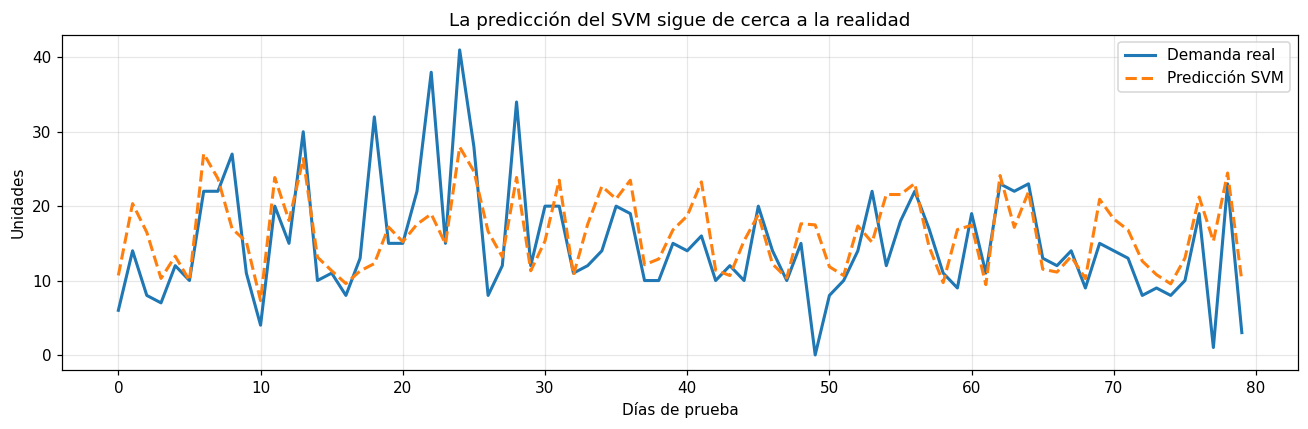

In [10]:
# grafico: real vs predicho en los primeros 80 dias de prueba
n = 80
plt.figure(figsize=(12, 4))
plt.plot(y_test[:n], label='Demanda real', lw=2)
plt.plot(pred[:n],   label='Predicción SVM', lw=2, ls='--')
plt.title('La predicción del SVM sigue de cerca a la realidad')
plt.xlabel('Días de prueba'); plt.ylabel('Unidades'); plt.legend()
plt.tight_layout(); plt.show()

## Paso 9 · ¿En qué se **fija** el modelo?

**En simple:** ¿qué pistas le importan más para decidir? Lo medimos *tapando* una
pista a la vez y viendo cuánto empeora: si tapar una pista arruina mucho la
predicción, esa pista era importante. Esto hace al modelo **transparente**: no es
una caja negra, sabemos *por qué* decide.

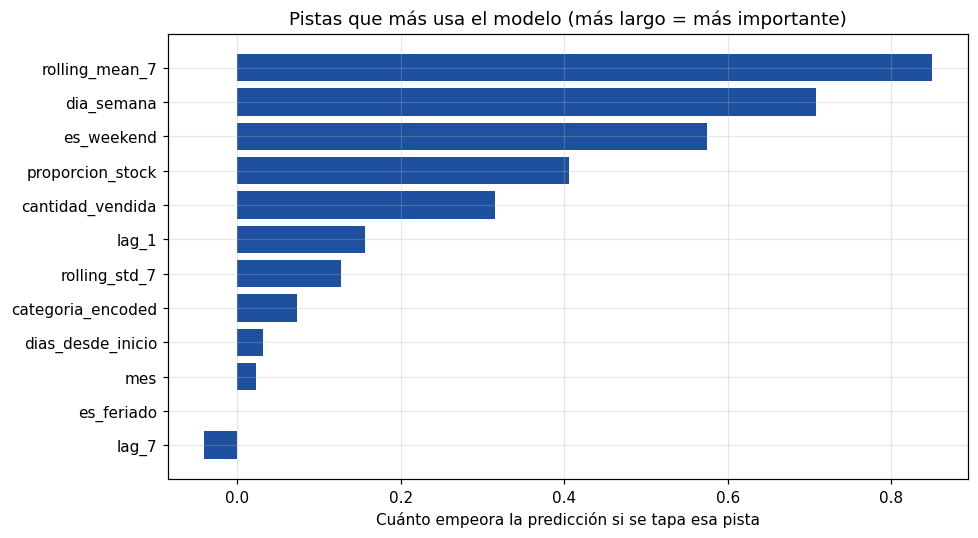

Top 3 pistas más importantes:
  - rolling_mean_7
  - dia_semana
  - es_weekend


In [11]:
from sklearn.inspection import permutation_importance
r = permutation_importance(svr, X_test, y_test, n_repeats=10,
                           scoring='neg_root_mean_squared_error', random_state=42)
imp = (pd.Series(r.importances_mean, index=FEATURES)
         .sort_values(ascending=True))
plt.figure(figsize=(9, 5))
plt.barh(imp.index, imp.values, color='#1e50a0')
plt.title('Pistas que más usa el modelo (más largo = más importante)')
plt.xlabel('Cuánto empeora la predicción si se tapa esa pista')
plt.tight_layout(); plt.show()
print('Top 3 pistas más importantes:')
for f in imp.sort_values(ascending=False).index[:3]:
    print('  -', f)

**Traducción al lenguaje del negocio:** el modelo se apoya sobre todo en **el
promedio reciente de ventas** y en **el calendario** (día de la semana / fin de
semana). Es decir, decide igual que decidiría un buen tendero con experiencia —
pero de forma automática y para 10 productos a la vez.

## Paso 10 · Resumen listo para las diapositivas

Cada punto puede ser **una diapositiva** (o un renglón), contado para cualquiera:

1. **El problema:** adivinar cuánto se venderá *mañana* (como el panadero con el pan).
2. **Los datos entran crudos:** un cuaderno de ventas (cada fila, una venta).
3. **Se ordenan:** un día, un producto, cuánto se vendió.
4. **Se crean 12 pistas:** calendario + pasado reciente + contexto del producto.
5. **El filtro empareja las escalas** para que ninguna pista pese de más (moneda común).
6. **La SVM decide con pocos días clave** (vectores de soporte) → ligera, sin GPU.
7. **Resultado:** el SVM **acierta más** que la Práctica 2 (menos error, mayor R²).
8. **Es transparente:** sabemos en qué se fija (promedio reciente + calendario).

> **Conclusión para la empresa:** un modelo **sencillo, rápido, explicable y
> económico** que **supera** a métodos más complejos. Eso es exactamente lo que un
> negocio quiere: confiable y fácil de entender.